<a href="https://colab.research.google.com/github/Astgenne-Moore/Term-Deposit-Opening-Decision/blob/main/Term%2BDeposit%2BOpening%2BDecision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Term Deposit Opening Decision

## import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.decomposition import FactorAnalysis
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix as cm
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_score
from sklearn.feature_selection import RFE
import statsmodels.api as sm
from sklearn.metrics import cohen_kappa_score
from sklearn.metrics import matthews_corrcoef

In [ ]:
# Load the dataset explicitly specifying the header row
df = pd.read_csv("bank-new-clients.csv", sep=",", header=0)

# Descriptive Analysis

In [ ]:
print("Describe Dataset","\n")
print(df.info())
print(df.head(10))
print(df.describe())


Describe Dataset 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             2000 non-null   int64  
 1   job             2000 non-null   object 
 2   marital         2000 non-null   object 
 3   education       2000 non-null   object 
 4   default         2000 non-null   object 
 5   housing         2000 non-null   object 
 6   loan            2000 non-null   object 
 7   contact         2000 non-null   object 
 8   month           2000 non-null   object 
 9   day_of_week     2000 non-null   object 
 10  duration        2000 non-null   int64  
 11  campaign        2000 non-null   int64  
 12  pdays           2000 non-null   int64  
 13  previous        2000 non-null   int64  
 14  poutcome        2000 non-null   object 
 15  emp.var.rate    2000 non-null   float64
 16  cons.price.idx  2000 non-null   float64
 17  cons.conf.idx 

## Continuous Variables

In [ ]:
print("Continuous Variables","\n")
continous_vars=df.describe().columns
print(continous_vars)

Continuous Variables 

Index(['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object')


In [ ]:
print("Categorical Variables","\n")
categorical_vars=df.describe(include=[object]).columns
print(categorical_vars)

Categorical Variables 

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome', 'y'],
      dtype='object')


## Visualizing - Continous Variables

Continuous Variables Visualization 



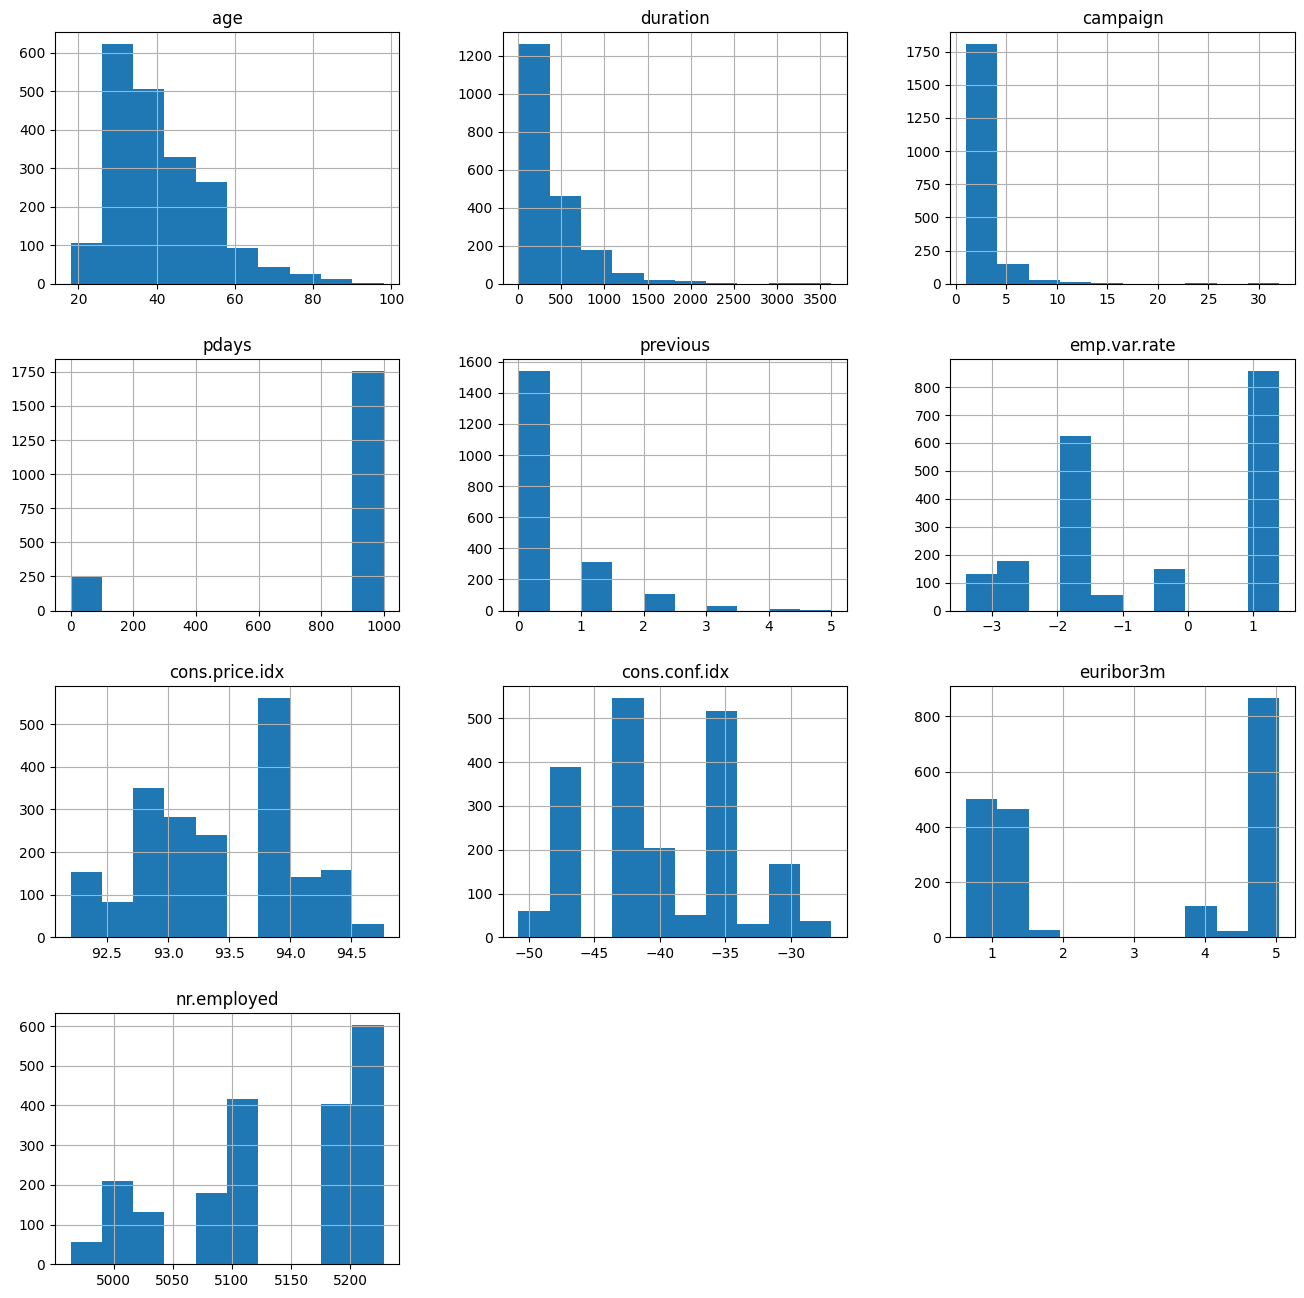

In [ ]:
print("Continuous Variables Visualization","\n")
df.hist(column=continous_vars,figsize=(16,16))
plt.show()

## Visualizing - Categorical Variables

Categorical Variables Visualization 



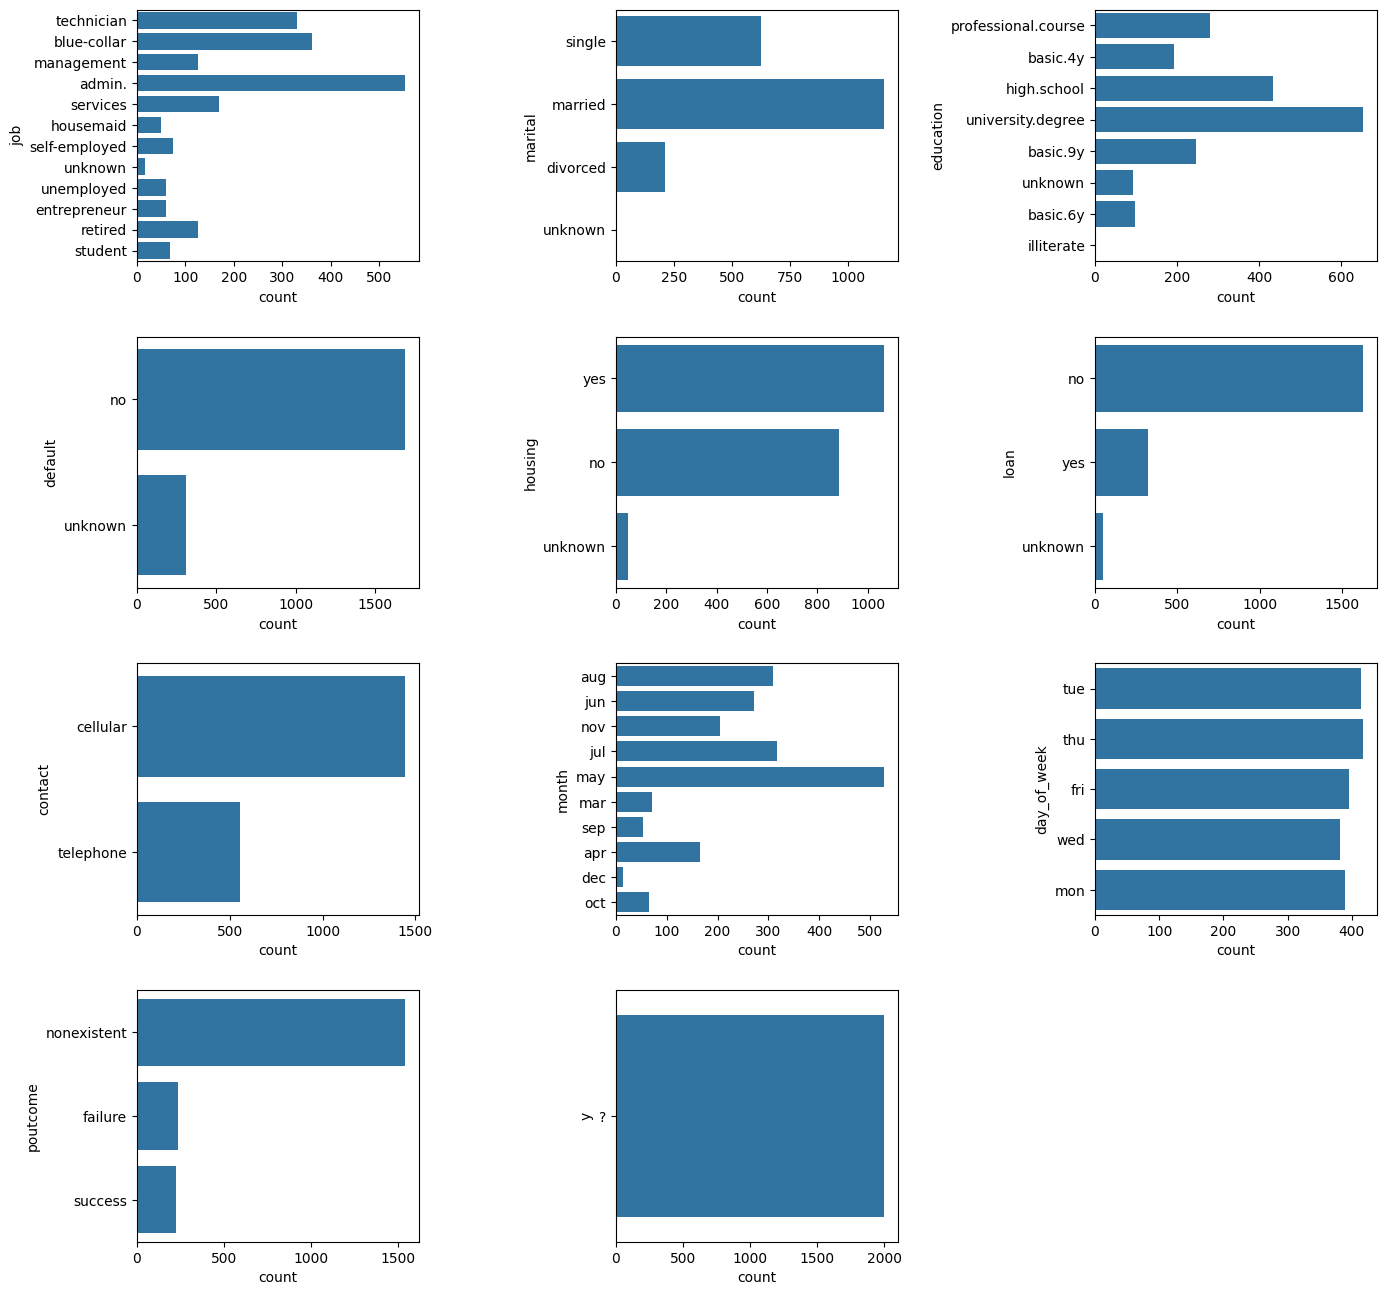

In [ ]:
print("Categorical Variables Visualization","\n")
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.7, hspace=0.3)
for i, ax in enumerate(axes.ravel()):
    if i > 10:
        ax.set_visible(False)
        continue
    sns.countplot(y = categorical_vars[i], data=df, ax=ax)
plt.show()

## Data Manipulation

In [ ]:
# Convert pdays column numeric to categorical
df["pdays_cat"]=[0 if each==999  else 1 for each in df.pdays]
df=df.drop(["pdays"],axis=1)

## Correlations

Correlation Matrix 



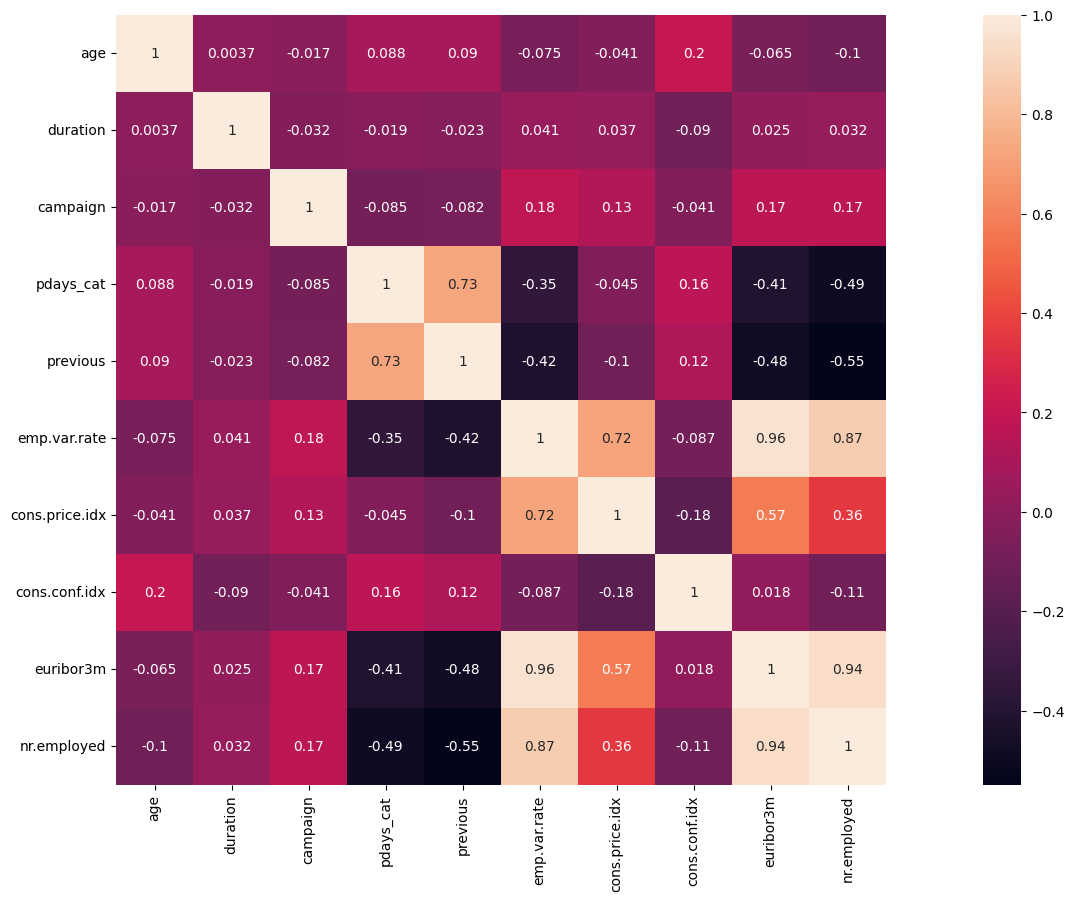

In [ ]:
continuous_columns = ['age', 'duration', 'campaign', 'pdays_cat', 'previous', 'emp.var.rate',
                      'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

# Subset the dataframe to only include the continuous variables
df_continuous = df[continuous_columns]
# Calculate the correlation matrix
correlation = df_continuous.corr(method="pearson")
# Plot the heatmap
print("Correlation Matrix", "\n")
plt.figure(figsize=(25, 10))
sns.heatmap(correlation, vmax=1, square=True, annot=True)
plt.show()

# Factor Analysis

In [ ]:
fact_2c=FactorAnalysis(n_components=1)
df["X_factor"]=fact_2c.fit_transform(df[['euribor3m','nr.employed','cons.price.idx','emp.var.rate']])
df=df.drop(["euribor3m","nr.employed","cons.price.idx","emp.var.rate"],axis=1)


## One - Hot Encoding

In [ ]:
columns = df.select_dtypes(include=[object]).columns
df = pd.concat([df, pd.get_dummies(df[columns])], axis=1)
df = df.drop(['job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week','poutcome', 'y','duration'], axis =1)
print("\n","Describe Dataset_v2","\n")
print(df.info(),"\n \n \n")


 Describe Dataset_v2 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 59 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   age                            2000 non-null   int64  
 1   campaign                       2000 non-null   int64  
 2   previous                       2000 non-null   int64  
 3   cons.conf.idx                  2000 non-null   float64
 4   pdays_cat                      2000 non-null   int64  
 5   X_factor                       2000 non-null   float64
 6   job_admin.                     2000 non-null   bool   
 7   job_blue-collar                2000 non-null   bool   
 8   job_entrepreneur               2000 non-null   bool   
 9   job_housemaid                  2000 non-null   bool   
 10  job_management                 2000 non-null   bool   
 11  job_retired                    2000 non-null   bool   
 12  job_self-employed       

In [ ]:
X = df.drop(columns=['y_?'])
y = df['y_?']
final_df = pd.concat([X, y], axis=1)
# Save for Weka
final_df.to_csv("term_deposit_unknown_weka.csv", index=False)

In [ ]:
import pandas as pd
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTENC
from collections import Counter

# Prepare features and target
X = df.drop(columns=['y_no', 'y_yes'])
y = df['y_yes'].astype(int)  # 1 = 'yes', 0 = 'no'

# Identify categorical columns
categorical_features = X.select_dtypes(include=['bool']).columns
categorical_indices = [X.columns.get_loc(col) for col in categorical_features]

# Convert booleans to integers
X_encoded = X.copy()
X_encoded[categorical_features] = X_encoded[categorical_features].astype(int)

# Apply SMOTETomek with SMOTENC
smote_nc = SMOTENC(categorical_features=categorical_indices, random_state=42)
smt = SMOTETomek(smote=smote_nc, random_state=42)
X_resampled, y_resampled = smt.fit_resample(X_encoded, y)

# Convert label back to "yes"/"no"
y_label = pd.Series(y_resampled).map({1: "yes", 0: "no"}).rename("y")


# Combine into final DataFrame
X_res_df = pd.DataFrame(X_resampled, columns=X.columns)
final_df = pd.concat([X_res_df, y_label], axis=1)

# Save for Weka
final_df.to_csv("term_deposit_balanced_weka.csv", index=False)

# Optional: check class balance
print("After resampling:", Counter(y_label))


'\n# Combine into final DataFrame\nX_res_df = pd.DataFrame(X_resampled, columns=X.columns)\nfinal_df = pd.concat([X_res_df, y_label], axis=1)\n\n# Save for Weka\nfinal_df.to_csv("term_deposit_balanced_weka.csv", index=False)\n\n# Optional: check class balance\nprint("After resampling:", Counter(y_label))\n'

In [ ]:
# Install necessary packages
!pip install shap boruta lightgbm xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.9/57.9 kB 2.4 MB/s eta 0:00:00



[RFECV] Selected features:
['age', 'campaign', 'previous', 'cons.conf.idx', 'X_factor', 'job_admin.', 'job_blue-collar', 'job_management', 'job_technician', 'marital_married', 'marital_single', 'education_basic.4y', 'education_basic.9y', 'education_high.school', 'education_professional.course', 'education_university.degree', 'default_no', 'default_unknown', 'housing_no', 'housing_yes', 'loan_no', 'loan_yes', 'contact_cellular', 'contact_telephone', 'month_aug', 'month_jul', 'month_jun', 'month_may', 'month_nov', 'day_of_week_fri', 'day_of_week_mon', 'day_of_week_thu', 'day_of_week_tue', 'day_of_week_wed', 'poutcome_failure', 'poutcome_nonexistent', 'poutcome_success']
[LightGBM] [Info] Number of positive: 3621, number of negative: 3621
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001887 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bin

/usr/local/lib/python3.11/dist-packages/shap/explainers/_tree.py:544: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(



[SHAP] Plotting feature importance:


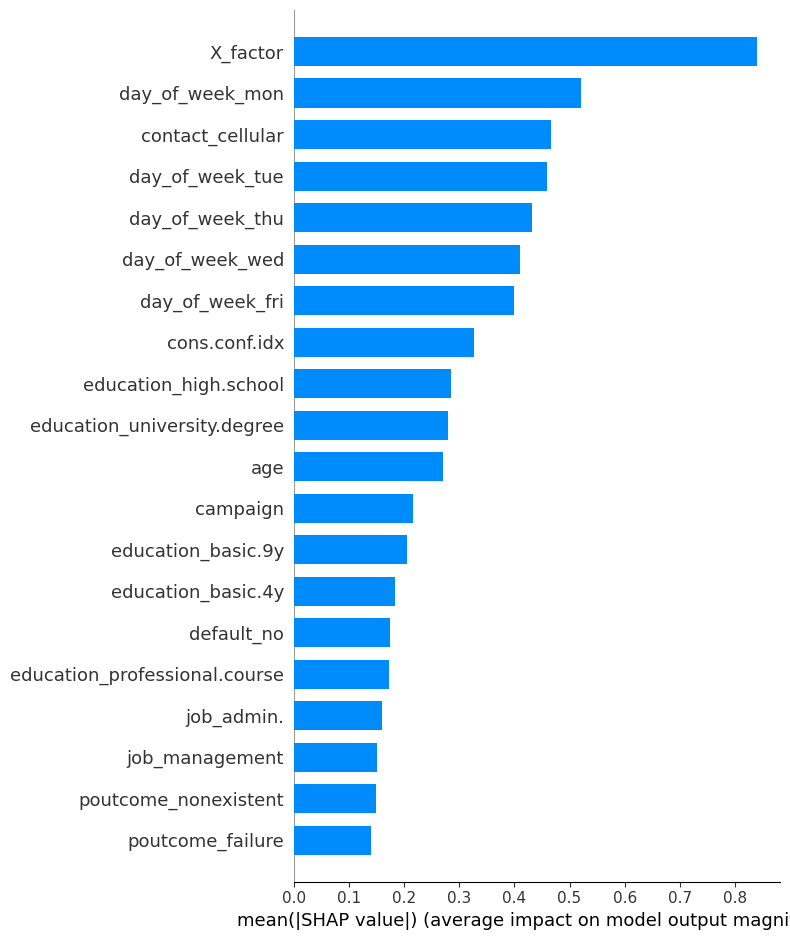


[SHAP] Top features:
X_factor                       0.839583
day_of_week_mon                0.521200
contact_cellular               0.465550
day_of_week_tue                0.458791
day_of_week_thu                0.432415
day_of_week_wed                0.410571
day_of_week_fri                0.399974
cons.conf.idx                  0.326456
education_high.school          0.285469
education_university.degree    0.279853
age                            0.270251
campaign                       0.215821
education_basic.9y             0.204514
education_basic.4y             0.182817
default_no                     0.174138
dtype: float64

[Boruta] Selected features:
['age', 'campaign', 'previous', 'cons.conf.idx', 'pdays_cat', 'X_factor', 'job_blue-collar', 'job_management', 'job_services', 'job_technician', 'marital_divorced', 'education_basic.4y', 'education_basic.6y', 'education_basic.9y', 'education_high.school', 'education_professional.course', 'default_no', 'default_unknown', 'housing_no'

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import RFECV, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from boruta import BorutaPy
import shap
import xgboost as xgb
import lightgbm as lgb
import matplotlib.pyplot as plt


X = X_resampled
y = y_label

# 1. Recursive Feature Elimination with CV (RFECV)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rfecv = RFECV(estimator=rf_model, step=1, cv=StratifiedKFold(5), scoring='accuracy', n_jobs=-1)
rfecv.fit(X, y)

rfecv_features = X.columns[rfecv.support_].tolist()
print("\n[RFECV] Selected features:")
print(rfecv_features)

# 2. SHAP with LightGBM
lgb_model = lgb.LGBMClassifier(n_estimators=100)
lgb_model.fit(X, y)

explainer = shap.TreeExplainer(lgb_model)
shap_values = explainer.shap_values(X)

print("\n[SHAP] Plotting feature importance:")
shap.summary_plot(shap_values, X, plot_type="bar")  # visual


shap_importance = np.abs(shap_values).mean(axis=0)
shap_top_features = pd.Series(shap_importance, index=X.columns).sort_values(ascending=False)
print("\n[SHAP] Top features:")
print(shap_top_features.head(15))

# 3. Boruta Feature Selection
boruta_rf = RandomForestClassifier(n_jobs=-1, class_weight='balanced', max_depth=5)
boruta_selector = BorutaPy(estimator=boruta_rf, n_estimators='auto', random_state=42)
boruta_selector.fit(X.values, y)

boruta_features = X.columns[boruta_selector.support_].tolist()
print("\n[Boruta] Selected features:")
print(boruta_features)


# 4. Mutual Information
mi_scores = mutual_info_classif(X, y)
mi_series = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)
print("\n[Mutual Info] Top features:")
print(mi_series.head(15))

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline

# Load dataset
df = pd.read_csv('term_deposit_balanced_weka.csv')

# ----------------------------
# STEP 1: Encode categorical variables (Label Encoding for tree models)
# ----------------------------
df_encoded = df.copy()
for col in df_encoded.select_dtypes(include='object').columns:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])

# ----------------------------
# STEP 2: Use only selected features
# ----------------------------
selected_features = [
              'X_factor',
              'cons.conf.idx',
              'contact_cellular',
              'contact_telephone',
              'poutcome_success',
              'campaign',
              'default_no',
              'default_unknown',
              'loan_no',
              'loan_yes',
              'poutcome_nonexistent',
              'pdays_cat',
              'education_basic.9y',
              'age',
              'day_of_week_tue',
              'job_blue-collar',
              'previous',
              'day_of_week_wed',
              'month_may',
              'day_of_week_fri',
              'job_management',
              'education_high.school',
              'marital_divorced',
              'day_of_week_thu',
              'education_basic.6y',
              'job_services',
              'education_professional.course',
]

X = df_encoded[selected_features]
y = df_encoded['y']

# ----------------------------
# STEP 3: Define parameter space
# ----------------------------
param_dist = {
    'n_estimators': [300, 500, 800, 1000],
    'max_depth': [10, 20, 30, 50, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None],
    'bootstrap': [True, False],
    'criterion': ['gini', 'entropy']
}

# ----------------------------
# STEP 4: Tune using RandomizedSearchCV
# ----------------------------
rf = RandomForestClassifier(random_state=42, n_jobs=-1)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=100,  # Large number for thorough search
    scoring='accuracy',
    cv=cv,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

# ----------------------------
# STEP 5: Run the search
# ----------------------------
random_search.fit(X, y)

# ----------------------------
# STEP 6: Show the best model
# ----------------------------
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Accuracy Score:")
print(random_search.best_score_)

# ----------------------------
# Optional: Retrain on full data with best params
# ----------------------------
best_model = random_search.best_estimator_
best_model.fit(X, y)

# Export if needed:
# import joblib
# joblib.dump(best_model, 'best_rf_model.pkl')

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best Parameters:
{'n_estimators': 800, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 30, 'criterion': 'gini', 'bootstrap': True}

Best Accuracy Score:
0.9338577948594763


RandomForestClassifier(max_depth=30, max_features='log2', n_estimators=800,
                       n_jobs=-1, random_state=42)

Fraction threshold: 0.019250025276551657
Percentage threshold: 0.047847600000000004


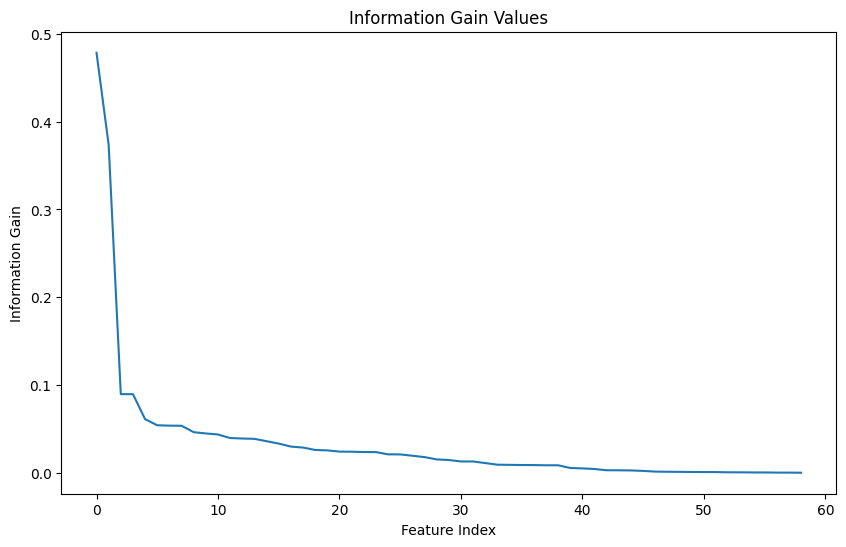

Non-zero threshold: 0
Features above fraction threshold: 27


In [ ]:
import numpy as np

# Information gain values
info_gains = [
    0.478476, 0.373615, 0.089525, 0.089525, 0.0610332, 0.0540707, 0.0536427,
    0.0535162, 0.0461876, 0.044751, 0.043573, 0.0395355, 0.0389815, 0.0385819,
    0.0359143, 0.0332176, 0.0297985, 0.028683, 0.0259499, 0.0254571, 0.0240621,
    0.0239487, 0.0235906, 0.023513, 0.0209435, 0.0208782, 0.0193781, 0.0178187,
    0.0151599, 0.0145147, 0.0128464, 0.0128409, 0.0110253, 0.0091486,
    0.0089894, 0.0087664, 0.0087317, 0.0084859, 0.0084859, 0.0053956, 0.0049398,
    0.0042311, 0.0028294, 0.0027735, 0.002608, 0.0020928, 0.001284, 0.0010922,
    0.0009999, 0.0008525, 0.000782, 0.0007414, 0.0004864, 0.0004536, 0.0003398,
    0.0003222, 0.0001381, 0.0001381, 0.000011
]

# Calculate the standard deviation
std_dev = np.std(info_gains)

# Option 1: Use a fraction of the standard deviation
fraction_threshold = 0.25 * std_dev
print(f"Fraction threshold: {fraction_threshold}")

# Option 2: Use a percentage of the maximum information gain
max_info_gain = max(info_gains)
percentage_threshold = 0.1 * max_info_gain
print(f"Percentage threshold: {percentage_threshold}")

# Option 3: Visual inspection (plotting)
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(sorted(info_gains, reverse=True))
plt.title('Information Gain Values')
plt.xlabel('Feature Index')
plt.ylabel('Information Gain')
plt.show()

# Option 4: Cross-validation (not shown here, requires model implementation)

# Option 5: Non-zero information gain
non_zero_threshold = 0
print(f"Non-zero threshold: {non_zero_threshold}")

# Example: Applying the fraction threshold
fraction_threshold_features = [gain for gain in info_gains if gain > fraction_threshold]
print(f"Features above fraction threshold: {len(fraction_threshold_features)}")


In [ ]:
# Define the lists of features
rfecv_features = ['age', 'campaign', 'previous', 'cons.conf.idx', 'X_factor', 'job_admin.', 'job_blue-collar', 'job_management', 'job_technician', 'marital_married', 'marital_single', 'education_basic.4y', 'education_basic.9y', 'education_high.school', 'education_professional.course', 'education_university.degree', 'default_no', 'default_unknown', 'housing_no', 'housing_yes', 'loan_no', 'loan_yes', 'contact_cellular', 'contact_telephone', 'month_aug', 'month_jul', 'month_jun', 'month_may', 'month_nov', 'day_of_week_fri', 'day_of_week_mon', 'day_of_week_thu', 'day_of_week_tue', 'day_of_week_wed', 'poutcome_failure', 'poutcome_nonexistent', 'poutcome_success']
shap_features = ['X_factor', 'day_of_week_mon', 'contact_cellular', 'day_of_week_tue', 'day_of_week_thu', 'day_of_week_wed', 'day_of_week_fri', 'cons.conf.idx', 'education_high.school', 'education_university.degree', 'age', 'campaign', 'education_basic.9y', 'education_basic.4y', 'default_no']
boruta_features = ['age', 'campaign', 'previous', 'cons.conf.idx', 'pdays_cat', 'X_factor', 'job_blue-collar', 'job_management', 'job_services', 'job_technician', 'marital_divorced', 'education_basic.4y', 'education_basic.6y', 'education_basic.9y', 'education_high.school', 'education_professional.course', 'default_no', 'default_unknown', 'housing_no', 'housing_yes', 'loan_no', 'loan_yes', 'contact_cellular', 'contact_telephone', 'month_aug', 'month_jul', 'month_jun', 'month_may', 'month_nov', 'day_of_week_fri', 'day_of_week_mon', 'day_of_week_thu', 'day_of_week_tue', 'day_of_week_wed', 'poutcome_failure', 'poutcome_nonexistent', 'poutcome_success']
mutual_info_features = ['X_factor', 'cons.conf.idx', 'contact_cellular', 'contact_telephone', 'poutcome_success', 'default_unknown', 'age', 'default_no', 'loan_yes', 'campaign', 'loan_no', 'poutcome_nonexistent', 'pdays_cat', 'day_of_week_wed', 'day_of_week_fri']

A = []
A = rfecv_features + shap_features + boruta_features + mutual_info_features
from collections import Counter
counts = Counter(A)
B = 0
for attribute, count in counts.items():
    B+=1
    print(f"{attribute}: {count}")

print(B)

age: 4
campaign: 4
previous: 2
cons.conf.idx: 4
X_factor: 4
job_admin.: 1
job_blue-collar: 2
job_management: 2
job_technician: 2
marital_married: 1
marital_single: 1
education_basic.4y: 3
education_basic.9y: 3
education_high.school: 3
education_professional.course: 2
education_university.degree: 2
default_no: 4
default_unknown: 3
housing_no: 2
housing_yes: 2
loan_no: 3
loan_yes: 3
contact_cellular: 4
contact_telephone: 3
month_aug: 2
month_jul: 2
month_jun: 2
month_may: 2
month_nov: 2
day_of_week_fri: 4
day_of_week_mon: 3
day_of_week_thu: 3
day_of_week_tue: 3
day_of_week_wed: 4
poutcome_failure: 2
poutcome_nonexistent: 3
poutcome_success: 3
pdays_cat: 2
job_services: 1
marital_divorced: 1
education_basic.6y: 1
41
